In [16]:
##COSTRUIAMO LA PROBABILITA' CALIBRATA###


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, RocCurveDisplay

from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show

In [17]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
column_names = [
    'Status', 'Duration', 'CreditHistory', 'Purpose', 'CreditAmount', 'Savings',
    'Employment', 'InstallmentRate', 'PersonalStatusSex', 'Debtors',
    'ResidenceDuration', 'Property', 'Age', 'InstallmentPlans', 'Housing',
    'ExistingCredits', 'Job', 'Liables', 'Telephone', 'ForeignWorker', 'class'
]
df = pd.read_csv("dataset1.data", sep=' ', header=None, names=column_names)


# Preprocessing
df['default'] = df['class'].map({1: 0, 2: 1})
df.drop(columns=['class'], inplace=True)

# One-hot encoding
X = pd.get_dummies(df.drop(columns=['default']), drop_first=True)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [18]:
from interpret.glassbox import ExplainableBoostingClassifier

ebm = ExplainableBoostingClassifier(
    # >>>  DEFAULT EBM 0.5.0  <<<
    random_state        = 42,      # stesso seed di sempre
    learning_rate       = 0.01,    # identico
    max_leaves          = 3,       # identico
    max_bins            = 128,     # 0.5.0 usava 128, non 256
    min_samples_leaf    = 2,       # identico
    outer_bags          = 8,       # 0.5.0 = 8  (ora 20)
    inner_bags          = 0,       # identico
    interactions        = 10,      # 0.5.0 default 10 (ora 0)
    max_interaction_bins= 32,      # identico
    early_stopping_rounds   = 400, # identico
    early_stopping_tolerance= 1e-4,# identico
    feature_names       = None,    # lasciamo gestire a EBM
    feature_types       = None,
    n_jobs              = None,    # 0.5.0 non impostava -1
    missing             = "gain",  # 0.5.0 instradava NaN su bin a guadagno maggiore
    # tutti gli altri param restano al default
)

ebm.fit(X_train, y_train)
y_pred_ebm  = ebm.predict(X_test)
y_prob_ebm  = ebm.predict_proba(X_test)[:, 1]





In [19]:
print("\n🌿 EBM")
print("Accuracy:", accuracy_score(y_test, y_pred_ebm))
print("AUC:", roc_auc_score(y_test, y_prob_ebm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ebm))


🌿 EBM
Accuracy: 0.7866666666666666
AUC: 0.8004232804232804
Confusion Matrix:
 [[194  16]
 [ 48  42]]


In [13]:
# Explainable Boosting Machine
ebm = ExplainableBoostingClassifier(random_state=42, interactions=10)
ebm.fit(X_train, y_train)
y_pred_ebm = ebm.predict(X_test)
y_prob_ebm = ebm.predict_proba(X_test)[:,1]
print('EBM Accuracy:', accuracy_score(y_test, y_pred_ebm))
print('EBM AUC:', roc_auc_score(y_test, y_prob_ebm))
print('Confusion Matrix:', confusion_matrix(y_test, y_pred_ebm))


Python(84498) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


EBM Accuracy: 0.8174666666666667
EBM AUC: 0.7796948655133594
Confusion Matrix: [[5547  294]
 [1075  584]]


In [20]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred_log = logreg.predict(X_test)
y_prob_log = logreg.predict_proba(X_test)[:, 1]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
# Probabilità predette
y_prob_ebm = ebm.predict_proba(X_test)[:, 1]
y_prob_log = logreg.predict_proba(X_test)[:, 1]

#estraiamo le probabilità di default (classe 1) per ciascun osservato nel set di test


# Brier Score
brier_ebm = brier_score_loss(y_test, y_prob_ebm)
brier_log = brier_score_loss(y_test, y_prob_log)

print(f"Brier EBM: {brier_ebm:.4f}")
print(f"Brier LogReg: {brier_log:.4f}")

# brier score --> È la media quadratica degli errori tra probabilità predetta e realtà.
#Più il Brier Score è basso → più le probabilità predette sono vicine alla realtà.

#> 0.25 indica scarsa calibrazione o modello troppo incerto

Brier EBM: 0.1577
Brier LogReg: 0.1553


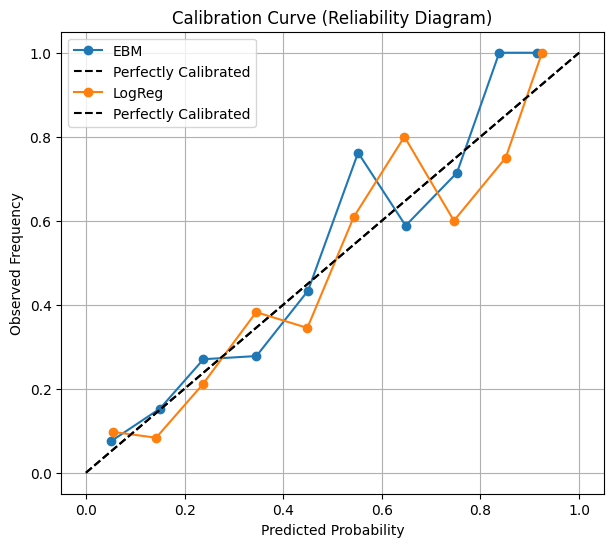

Brier EBM: 0.1577
Brier LogReg: 0.1553


In [22]:
def plot_calibration(y_true, prob_preds, model_name):
    prob_true, prob_pred = calibration_curve(y_true, prob_preds, n_bins=10, strategy='uniform')

    plt.plot(prob_pred, prob_true, marker='o', label=f'{model_name}')
    plt.plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')
    plt.xlabel('Predicted Probability')
    plt.ylabel('Observed Frequency')
    plt.title('Calibration Curve (Reliability Diagram)')
    plt.grid(True)

plt.figure(figsize=(7, 6))
plot_calibration(y_test, y_prob_ebm, 'EBM')
plot_calibration(y_test, y_prob_log, 'LogReg')
plt.legend()
plt.show()


print(f"Brier EBM: {brier_ebm:.4f}")
print(f"Brier LogReg: {brier_log:.4f}")


#I modelli sottostimano la probabilità di default intorno ai gruppi con 60%
#comunque Non è strettamente necessario ricalibrare, i modelli si comportano in modo simile e comunque vicino alla diagonale, con un basso brier score

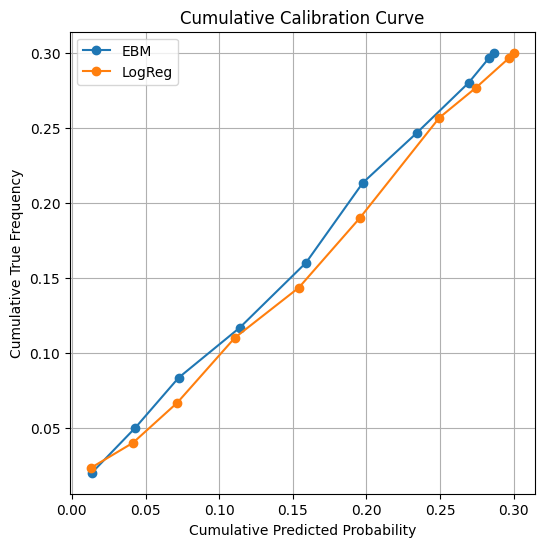

ECE EBM : 0.0436
ECE Log : 0.0654


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve


def plot_cumulative_calibration(y_true, y_prob, model_name, bins=10):
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=bins, strategy="uniform")

    bin_ids = np.digitize(y_prob, np.linspace(0, 1, bins + 1)) - 1
    bin_ids = np.clip(bin_ids, 0, bins - 1)  # evita indici fuori range

    count = np.bincount(bin_ids, minlength=bins)

    cum_pred = np.cumsum(prob_pred * count) / len(y_true)
    cum_true = np.cumsum(prob_true * count) / len(y_true)

    plt.plot(cum_pred, cum_true, marker="o", label=model_name)
    plt.xlabel("Cumulative Predicted Probability")
    plt.ylabel("Cumulative True Frequency")
    plt.title("Cumulative Calibration Curve")
    plt.grid(True)


plt.figure(figsize=(6, 6))
plot_cumulative_calibration(y_test, y_prob_ebm,  "EBM")
plot_cumulative_calibration(y_test, y_prob_log,  "LogReg")
plt.legend()
plt.show()

import numpy as np

def expected_calibration_error(y_true, y_prob, bins=10):
    """
    Calcola l'ECE (media pesata delle deviazioni assolute).
    """
    bin_edges = np.linspace(0, 1, bins + 1)
    bin_ids = np.digitize(y_prob, bin_edges[1:-1], right=True)

    ece = 0.0
    for i in range(bins):
        mask = bin_ids == i
        if np.any(mask):
            pred_prob = y_prob[mask].mean()
            true_frac = y_true[mask].mean()
            ece += np.abs(true_frac - pred_prob) * mask.mean()  # peso = n_i / N
    return ece

ece_ebm  = expected_calibration_error(y_test, y_prob_ebm)
ece_log  = expected_calibration_error(y_test, y_prob_log)

print(f"ECE EBM : {ece_ebm:.4f}")
print(f"ECE Log : {ece_log:.4f}")

#Mostra se l’intero modello sovra/sottostima il rischio in modo sistematico
#ebm sottostima leggermente, logistica sovrastima leggermente. logistica + conservativa--> migliore.


# ECE --> media pesata degli errori assoluti per bin
   #serve a Quantificare quanto la PD stimata è lontana da quella reale

#brier --> penalizza gli errori più evidenti
#ECE --> penalizza il fatto di fare più errori

# ECE per ebm --> Deviazione media assoluta del 4.4 % fra PD e realtà.   

#ebm fa più errori sparsi (brier + alto della logistica)
#ma nelle classi più numerose (bin centrali) la PD è più vicina alla realtà (ECE migliore).

In [14]:
import numpy as np

def expected_calibration_error(y_true, y_prob, bins=10):
    """
    Calcola l'ECE (media pesata delle deviazioni assolute).
    """
    bin_edges = np.linspace(0, 1, bins + 1)
    bin_ids = np.digitize(y_prob, bin_edges[1:-1], right=True)

    ece = 0.0
    for i in range(bins):
        mask = bin_ids == i
        if np.any(mask):
            pred_prob = y_prob[mask].mean()
            true_frac = y_true[mask].mean()
            ece += np.abs(true_frac - pred_prob) * mask.mean()  # peso = n_i / N
    return ece

ece_ebm  = expected_calibration_error(y_test, y_prob_ebm)
ece_log  = expected_calibration_error(y_test, y_prob_log)

print(f"ECE EBM : {ece_ebm:.4f}")
print(f"ECE Log : {ece_log:.4f}")



ECE EBM : 0.0436
ECE Log : 0.0654


In [ ]:
#Expected Loss (EL)	Stimare la perdita media su clienti/prestiti

In [23]:
print("🔎 Valore massimo di probabilità predetta da EBM:", y_prob_ebm.max())
print("🔎 Valore massimo di probabilità predetta da LogReg:", y_prob_log.max())


🔎 Valore massimo di probabilità predetta da EBM: 0.9140909706007692
🔎 Valore massimo di probabilità predetta da LogReg: 0.9247460006675454
